Compare rock segmentation errors and oracle corrections between the short and long supervised baselines using saved confusion matrices.

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RUNS = {
    "Short": "baseline_r50_short_1xHeadLR",
    "Full": "baseline_r50_full_1xHeadLR",
}
SPLIT = "test"
CLASSES = ["sky", "ridge", "soil", "sand", "bedrock", "rock", "rover", "trace", "hole"]
ROCK = CLASSES.index("rock")

# Project paths
project_dir = Path.cwd()
if project_dir.name.lower() == "analysis":
    project_dir = project_dir.parent
results_dir = project_dir / "results"
output_dir = project_dir / "analysis" / "results" / "MS-28"
output_dir.mkdir(parents=True, exist_ok=True)

# Load confusion matrices
matrices = {}
for label, run_name in RUNS.items():
    path = results_dir / run_name / SPLIT / "confusion.npy"
    if not path.exists():
        raise FileNotFoundError(path)
    cm = np.load(path)
    matrices[label] = cm
    print(f"{label}: {run_name} ({SPLIT})")

Short: baseline_r50_short_1xHeadLR (test)
Full: baseline_r50_full_1xHeadLR (test)


### Full 9-Class Confusion Matrices (Short vs. Full)

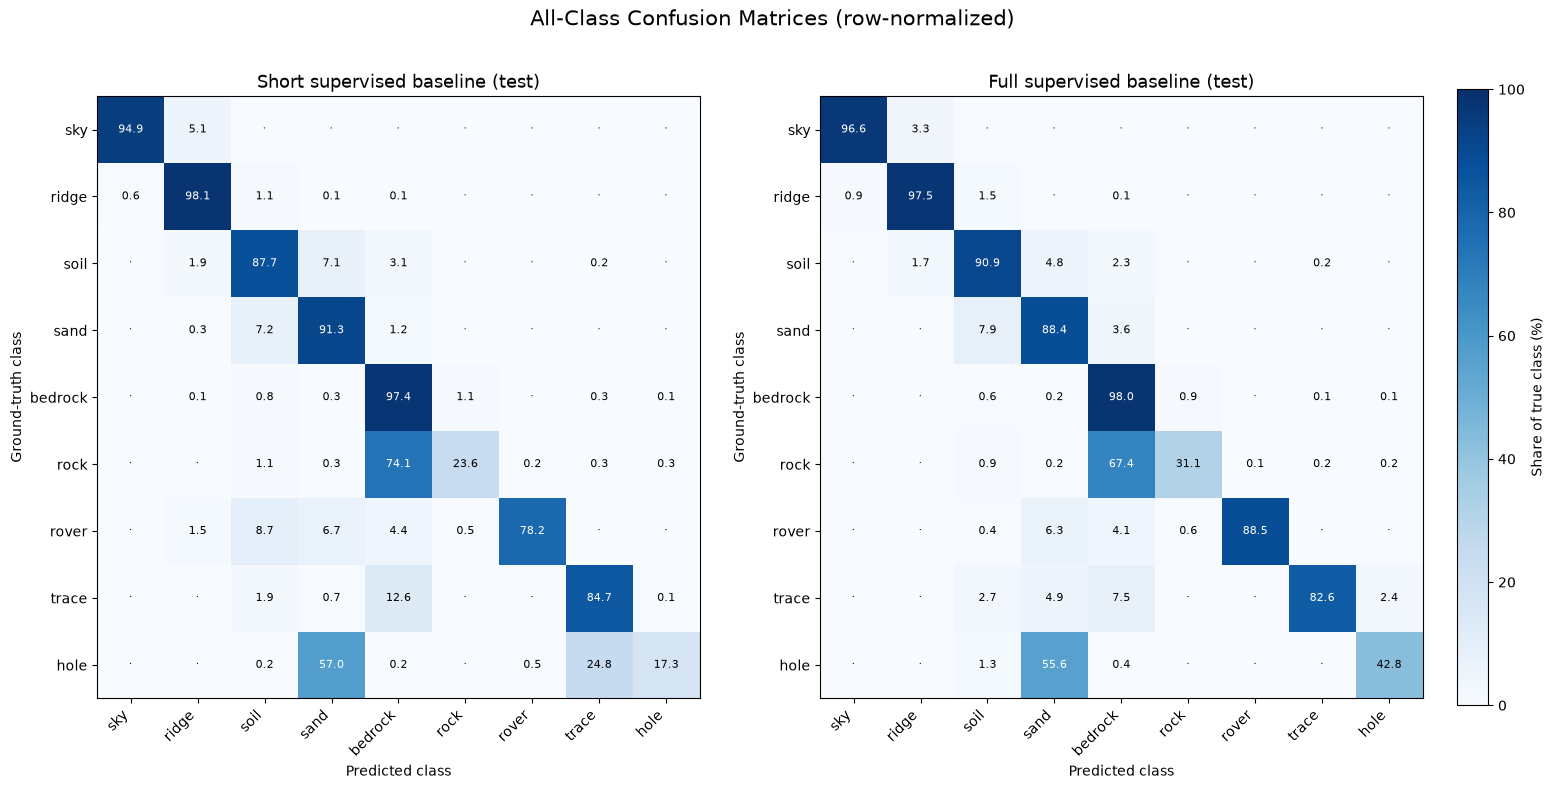

In [12]:
# Full 9-class confusion matrices
fig, axes = plt.subplots(1, len(matrices), figsize=(18, 8))
axes = np.atleast_1d(axes)

for ax, (label, cm) in zip(axes, matrices.items()):
    if cm.shape != (len(CLASSES), len(CLASSES)):
        raise ValueError(f"{label}: expected {len(CLASSES)}x{len(CLASSES)} confusion matrix, got {cm.shape}")
    
    row_totals = cm.sum(axis=1, keepdims=True)
    cm_pct = np.divide(
        cm.astype(np.float64) * 100,
        row_totals,
        out=np.zeros_like(cm, dtype=np.float64),
        where=row_totals != 0,
    )
    pd.DataFrame(cm_pct, index=CLASSES, columns=CLASSES).to_csv(
        output_dir / f"confusion_all_classes_{label.lower()}_{SPLIT}_row_pct.csv",
        index_label="true_class",
    )

    heatmap = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100, interpolation="nearest")
    ax.set_title(f"{label} supervised baseline ({SPLIT})", fontsize=13)
    ax.set_xticks(np.arange(len(CLASSES)), CLASSES, rotation=45, ha="right")
    ax.set_yticks(np.arange(len(CLASSES)), CLASSES)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Ground-truth class")

    # Annotate each cell with its share of the ground-truth class, in %.
    for row in range(len(CLASSES)):
        for col in range(len(CLASSES)):
            value = cm_pct[row, col]
            annotation = f"{value:.1f}" if value >= 0.05 else "·"
            ax.text(
                col, row, annotation,
                ha="center", va="center",
                color="white" if value >= 55 else "black",
                fontsize=8,
            )

fig.colorbar(heatmap, ax=axes, fraction=0.025, pad=0.025, label="Share of true class (%)")
fig.suptitle("All-Class Confusion Matrices (row-normalized)", fontsize=15, y=0.98)
fig.savefig(output_dir / f"confusion_all_classes_{SPLIT}.png", dpi=250, bbox_inches="tight")
plt.show()


,baseline,class,rock_FN,rock_FN_pct,rock_FP,rock_FP_pct
0,Short,sky,1291,0.01,0,0.00
1,Short,ridge,1142,0.01,0,0.00
2,Short,soil,155949,1.44,14771,0.65
3,Short,sand,46076,0.42,14,0.00
4,Short,bedrock,10524947,97.01,2242757,99.12
5,Short,rover,29705,0.27,5212,0.23
6,Short,trace,45036,0.42,0,0.00
7,Short,hole,45484,0.42,0,0.00
8,Full,sky,698,0.01,0,0.00
9,Full,ridge,804,0.01,0,0.00


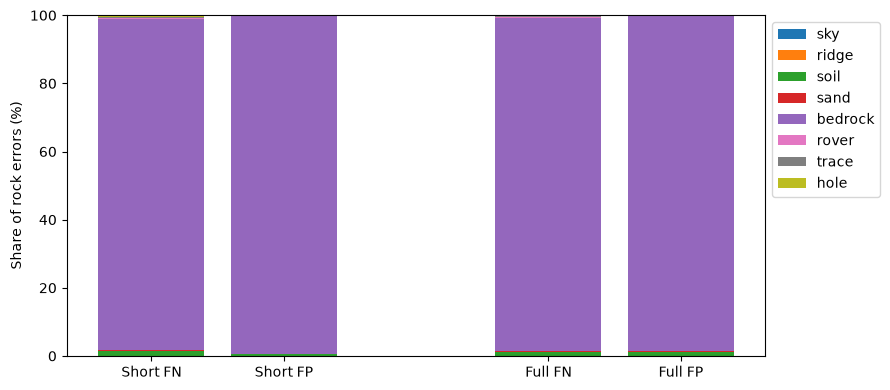

In [13]:
def get_iou(cm):
    tp = np.diag(cm)
    union = cm.sum(axis=0) + cm.sum(axis=1) - tp
    return np.divide(tp, union, out=np.full(9, np.nan), where=union > 0)

def get_oracle_matrix(cm, a, b):
    corrected = cm.copy()
    corrected[a, a] += cm[a, b]
    corrected[b, b] += cm[b, a]
    corrected[a, b] = 0
    corrected[b, a] = 0
    return corrected

error_rows = []
for label, cm in matrices.items():
    rock_fn = cm[ROCK].sum() - cm[ROCK, ROCK]
    rock_fp = cm[:, ROCK].sum() - cm[ROCK, ROCK]
    for i, name in enumerate(CLASSES):
        if i == ROCK:
            continue
        fn = int(cm[ROCK, i])
        fp = int(cm[i, ROCK])
        error_rows.append({
            "baseline": label,
            "class": name,
            "rock_FN": fn,
            "rock_FN_pct": 100 * fn / rock_fn if rock_fn else 0,
            "rock_FP": fp,
            "rock_FP_pct": 100 * fp / rock_fp if rock_fp else 0,
        })

error_df = pd.DataFrame(error_rows)
error_df.to_csv(output_dir / "rock_error_sources.csv", index=False)
display(error_df.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
positions = []
labels = []
for j, label in enumerate(matrices):
    one = error_df[error_df["baseline"] == label].set_index("class")
    for k, column in enumerate(["rock_FN_pct", "rock_FP_pct"]):
        x = j * 3 + k
        bottom = 0
        for i, name in enumerate(CLASSES):
            if name == "rock":
                continue
            value = float(one.loc[name, column])
            ax.bar(x, value, bottom=bottom, color=plt.cm.tab10(i), label=name if x == 0 else None)
            bottom += value
        positions.append(x)
        labels.append(label + (" FN" if k == 0 else " FP"))
ax.set_xticks(positions, labels)
ax.set_ylabel("Share of rock errors (%)")
ax.set_ylim(0, 100)
ax.legend(bbox_to_anchor=(1, 1), loc="upper left")
plt.tight_layout()
plt.savefig(output_dir / "rock_error_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

,baseline,pair,a_to_b,b_to_a,rock_IoU_before,rock_IoU_after,rock_IoU_gain_pp,mIoU_before,mIoU_after,mIoU_gain_pp
0,Short,rock <-> bedrock,10524947,2242757,20.34,97.58,77.23,67.75,76.96,9.22
1,Short,rock <-> soil,155949,14771,20.34,21.31,0.97,67.75,67.88,0.13
2,Short,rock <-> sand,46076,14,20.34,20.62,0.28,67.75,67.79,0.04
3,Short,soil <-> sand,4372254,1652999,20.34,20.34,0.00,67.75,70.94,3.19
4,Full,rock <-> bedrock,9564737,1875451,27.39,98.22,70.83,73.60,82.04,8.45
5,Full,rock <-> soil,122622,24462,27.39,28.20,0.80,73.60,73.71,0.11
6,Full,rock <-> sand,25377,502,27.39,27.55,0.16,73.60,73.62,0.03
7,Full,soil <-> sand,2979048,1823807,27.39,27.39,0.00,73.60,76.25,2.65


,baseline,direction,count,share_of_class_FN_pct
0,Short,soil -> sand,4372254,57.85
1,Short,sand -> soil,1652999,82.62
2,Full,soil -> sand,2979048,53.27
3,Full,sand -> soil,1823807,68.73


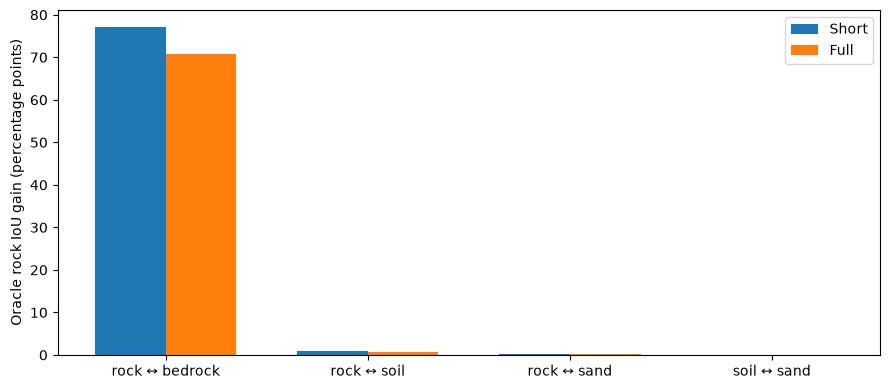

In [14]:
PAIRS = [("rock", "bedrock"), ("rock", "soil"), ("rock", "sand"), ("soil", "sand")]
rows = []
soil_sand_rows = []

for label, cm in matrices.items():
    before = get_iou(cm)
    before_miou = np.nanmean(before)
    for name_a, name_b in PAIRS:
        a = CLASSES.index(name_a)
        b = CLASSES.index(name_b)
        corrected = get_oracle_matrix(cm, a, b)
        after = get_iou(corrected)
        rows.append({
            "baseline": label,
            "pair": name_a + " <-> " + name_b,
            "a_to_b": int(cm[a, b]),
            "b_to_a": int(cm[b, a]),
            "rock_IoU_before": 100 * before[ROCK],
            "rock_IoU_after": 100 * after[ROCK],
            "rock_IoU_gain_pp": 100 * (after[ROCK] - before[ROCK]),
            "mIoU_before": 100 * before_miou,
            "mIoU_after": 100 * np.nanmean(after),
            "mIoU_gain_pp": 100 * (np.nanmean(after) - before_miou),
        })
    soil = CLASSES.index("soil")
    sand = CLASSES.index("sand")
    for a, b in [(soil, sand), (sand, soil)]:
        fn_total = cm[a].sum() - cm[a, a]
        soil_sand_rows.append({
            "baseline": label,
            "direction": CLASSES[a] + " -> " + CLASSES[b],
            "count": int(cm[a, b]),
            "share_of_class_FN_pct": 100 * cm[a, b] / fn_total if fn_total else 0,
        })

oracle_df = pd.DataFrame(rows)
soil_sand_df = pd.DataFrame(soil_sand_rows)
oracle_df.to_csv(output_dir / "oracle_comparison.csv", index=False)
soil_sand_df.to_csv(output_dir / "soil_sand_errors.csv", index=False)
display(oracle_df.round(2))
display(soil_sand_df.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(PAIRS))
width = 0.35
for j, label in enumerate(matrices):
    one = oracle_df[oracle_df["baseline"] == label]
    ax.bar(x + (j - (len(matrices) - 1) / 2) * width,
           one["rock_IoU_gain_pp"], width, label=label)
ax.set_xticks(x, [a + " ↔ " + b for a, b in PAIRS])
ax.set_ylabel("Oracle rock IoU gain (percentage points)")
ax.legend()
plt.tight_layout()
plt.savefig(output_dir / "oracle_gain_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

In [15]:
summary_rows = []
for label, cm in matrices.items():
    rock_fn = cm[ROCK].sum() - cm[ROCK, ROCK]
    rock_fp = cm[:, ROCK].sum() - cm[ROCK, ROCK]
    bedrock = CLASSES.index("bedrock")
    rb = oracle_df[(oracle_df["baseline"] == label) & (oracle_df["pair"] == "rock <-> bedrock")].iloc[0]
    rs = oracle_df[(oracle_df["baseline"] == label) & (oracle_df["pair"] == "rock <-> soil")].iloc[0]
    rd = oracle_df[(oracle_df["baseline"] == label) & (oracle_df["pair"] == "rock <-> sand")].iloc[0]
    ss = oracle_df[(oracle_df["baseline"] == label) & (oracle_df["pair"] == "soil <-> sand")].iloc[0]
    summary_rows.append({
        "baseline": label,
        "run": RUNS[label],
        "rock_IoU_pct": 100 * get_iou(cm)[ROCK],
        "mIoU_pct": 100 * np.nanmean(get_iou(cm)),
        "rock_FN_pixels": int(rock_fn),
        "rock_FP_pixels": int(rock_fp),
        "rock_to_bedrock_pct_of_FN": 100 * cm[ROCK, bedrock] / rock_fn if rock_fn else 0,
        "bedrock_to_rock_pct_of_FP": 100 * cm[bedrock, ROCK] / rock_fp if rock_fp else 0,
        "RB_oracle_rock_IoU_after_pct": rb["rock_IoU_after"],
        "RB_oracle_rock_IoU_gain_pp": rb["rock_IoU_gain_pp"],
        "RS_oracle_rock_IoU_gain_pp": rs["rock_IoU_gain_pp"],
        "RD_oracle_rock_IoU_gain_pp": rd["rock_IoU_gain_pp"],
        "RB_oracle_mIoU_gain_pp": rb["mIoU_gain_pp"],
        "SS_oracle_mIoU_gain_pp": ss["mIoU_gain_pp"],
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(output_dir / "short_vs_long_summary.csv", index=False)
display(summary_df.set_index("baseline").drop(columns="run").T.rename_axis(columns="Comparison").round(2))

Comparison,Short,Full
rock_IoU_pct,20.34,27.39
mIoU_pct,67.75,73.60
rock_FN_pixels,10849630.00,9786513.00
rock_FP_pixels,2262754.00,1906948.00
rock_to_bedrock_pct_of_FN,97.01,97.73
bedrock_to_rock_pct_of_FP,99.12,98.35
RB_oracle_rock_IoU_after_pct,97.58,98.22
RB_oracle_rock_IoU_gain_pp,77.23,70.83
RS_oracle_rock_IoU_gain_pp,0.97,0.80
RD_oracle_rock_IoU_gain_pp,0.28,0.16


### Analysis

We compared the short (40k iterations) and full (150k iterations) supervised baselines on the test set. Rock IoU improved from 20.34% to 27.39%, while mIoU increased from 67.75% to 73.60%. However, rock–bedrock confusion remained dominant. Bedrock accounted for 97.01% and 97.73% of rock false negatives in the short and full baselines, respectively, and over 98% of rock false positives originated from bedrock in both models.

The rock–bedrock oracle correction improved rock IoU by 77.23 and 70.83 percentage points, substantially more than rock–soil or rock–sand corrections. These results strongly support H1: rock–bedrock confusion is the primary source of rock segmentation errors, even after longer training. We also observed notable soil–sand confusion, with oracle corrections improving mIoU by 3.19 and 2.65 points.

These oracle gains represent theoretical upper bounds rather than achievable improvements. Additionally, the analysis only considers labeled pixels and does not include Easy/Hard subset or per-image comparisons.